In [15]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import pro_ang1
import time


In [16]:
def Orders(s):
    """Return (i, j) with (i + 1)(j + 1) <= s + 1."""
    return [
        (i, j)
        for i in range(s + 1)
        for j in range((s + 1) // (i + 1))
    ]

In [17]:

# Experiment parameters

# Training sample sizes: 10 logarithmically spaced values
# from max_order_HC to 10,000
max_order_HC = 100
#Nsamples = np.logspace(np.log10(max_order_HC), np.log10(10_000), 10).astype(int)
Nsamples = np.logspace(2, 4, 10).astype(int)

# Hyperbolic-cross order parameters
Para_slep = np.linspace(1, max_order_HC, 5).astype(int)

# Number of independent repetitions
total_runs = 20

In [18]:
# Generate random sample points uniformly on [-1, 1]^2
rng = np.random.default_rng(42)

def generate_samples(n_samples):
    """Generate independent uniform samples on [-1, 1]^2."""
    return rng.uniform(-1, 1, size=(int(n_samples), 2))

In [29]:
# Compute the L2 norms of the angular Slepian functions

bandwidth = 16
n_quad = 1001

# Exclude the endpoints where pro_ang1 returns non-finite values
theta = np.linspace(-1, 1, n_quad + 2)[1:-1]
#theta = np.linspace(-1, 1, 200)

def slepian_norm(j, c=bandwidth):
    """Numerically approximate the L2 norm on [-1, 1]."""
    values = pro_ang1(0, j, c, theta)[0]

    if not np.isfinite(values).all():
        raise ValueError(f"Non-finite Slepian values for order j={j}")

    return np.sqrt(np.trapezoid(values**2, theta))

norms_ = np.array([
    slepian_norm(j) for j in range(Para_slep[-1] + 1)
])

print("All norms finite:", np.isfinite(norms_).all())
print("All norms positive:", np.all(norms_ > 0))
print("First 5 norms:", norms_[:5])


All norms finite: True
All norms positive: True
First 5 norms: [0.66981895 0.12146252 0.4867724  0.15616975 0.4365606 ]


In [30]:
# Evaluate the normalized angular Slepian basis function

def PSWF(x, j, c, norms_):
    """Evaluate the j-th normalized angular Slepian function at x."""
    psaf_values = pro_ang1(0, j, c, x)[0]
    return psaf_values / norms_[j]



In [31]:
# Compute products of two normalized Slepian basis functions

def product_of_pswf(x1, x2, i, j, c, norms_):
    """Evaluate psi_i(x1) * psi_j(x2)."""
    pswf1 = PSWF(x1, i, c, norms_)
    pswf2 = PSWF(x2, j, c, norms_)
    return pswf1 * pswf2

In [32]:
# Build the 2D hyperbolic-cross design matrix

bandwidth = 16

def Matrix(samples, k):
    """Build the design matrix for the 2D hyperbolic-cross basis.

    Parameters
    ----------
    samples : ndarray, shape (n_samples, 2)
        Sample points in [-1, 1]^2.
    k : int
        Hyperbolic-cross order parameter.

    Returns
    -------
    A : ndarray, shape (n_samples, n_basis)
        Matrix whose columns are products of normalized Slepian functions.
    """
    orders = Orders(k)
    A = np.empty((len(samples), len(orders)))

    for col, (i, j) in enumerate(orders):
        A[:, col] = product_of_pswf(
            samples[:, 0], samples[:, 1], i, j, bandwidth, norms_
        )

    return A

In [33]:
# This is the function that we approximate
def funct(samples):
    """Evaluate f2(x, y) = cos(0.2x) cos(0.2y) exp(-pi(x^2 + y^2))."""
    x, y = samples[:, 0], samples[:, 1]
    return (
        np.cos(0.2 * x)
        * np.cos(0.2 * y)
        * np.exp(-np.pi * (x**2 + y**2))
    )


In [64]:

# Fast evaluation of the normalized angular Slepian basis
from scipy.interpolate import CubicSpline

max_basis_order = int(max(Para_slep))
n_interp = 4001

# Chebyshev nodes strictly inside (-1, 1)
grid = np.sort(
    np.cos(np.pi * (np.arange(n_interp) + 0.5) / n_interp)
)

# Precompute the normalized basis functions on the grid
basis_grid = np.empty((n_interp, max_basis_order + 1))

for j in range(max_basis_order + 1):
    values, _ = pro_ang1(0, j, bandwidth, grid)
    basis_grid[:, j] = values / norms_[j]

    if (j + 1) % 10 == 0 or j == max_basis_order:
        print(f"Precomputed orders 0 through {j}", flush=True)

# Construct the interpolator
basis_interpolator = CubicSpline(
    grid, basis_grid, axis=0, extrapolate=True
)


def angular_basis(samples_1d, max_order, c=bandwidth):
    """Evaluate normalized angular Slepian functions."""
    if not np.isclose(c, bandwidth):
        raise ValueError("Interpolator uses the current bandwidth only.")
    if max_order > max_basis_order:
        raise ValueError("Requested order exceeds the precomputed maximum.")

    samples_1d = np.asarray(samples_1d)
    values = basis_interpolator(samples_1d)[:, :max_order + 1]

    for j in (50, 75):
        if max_order >= j:
            exact_values, _ = pro_ang1(0, j, c, samples_1d)
            values[:, j] = exact_values / norms_[j]

    return values


def Matrix_from_basis(Bx, By, k):
    """Build the 2D design matrix from precomputed 1D basis values."""
    orders = Orders(k)
    A = np.empty((Bx.shape[0], len(orders)))

    for col, (i, j) in enumerate(orders):
        A[:, col] = Bx[:, i] * By[:, j]

    return A


def Matrix(samples, k):
    """Build the 2D design matrix for a set of sample points."""
    max_order = max(i for i, j in Orders(k))
    Bx = angular_basis(samples[:, 0], max_order)
    By = angular_basis(samples[:, 1], max_order)
    return Matrix_from_basis(Bx, By, k)


# Validate interpolation against direct evaluations
rng_check = np.random.default_rng(12345)
x_check = rng_check.uniform(-1, 1, 200)
orders_check = [0, 25, 50, 75, 100]

print("\nChecking interpolation accuracy:", flush=True)

for j in orders_check:
    direct = pro_ang1(0, j, bandwidth, x_check)[0] / norms_[j]
    approx = angular_basis(x_check, j)[:, j]

    abs_error = np.max(np.abs(direct - approx))
    rel_error = (
        np.linalg.norm(direct - approx)
        / max(np.linalg.norm(direct), np.finfo(float).eps)
    )

    print(
        f"j={j:3d}: max abs error={abs_error:.3e}, "
        f"relative L2 error={rel_error:.3e}",
        flush=True
    )



Precomputed orders 0 through 9
Precomputed orders 0 through 19
Precomputed orders 0 through 29
Precomputed orders 0 through 39
Precomputed orders 0 through 49
Precomputed orders 0 through 59
Precomputed orders 0 through 69
Precomputed orders 0 through 79
Precomputed orders 0 through 89
Precomputed orders 0 through 99
Precomputed orders 0 through 100

Checking interpolation accuracy:
j=  0: max abs error=9.406e-13, relative L2 error=3.524e-13
j= 25: max abs error=1.238e-09, relative L2 error=4.776e-10
j= 50: max abs error=0.000e+00, relative L2 error=0.000e+00
j= 75: max abs error=0.000e+00, relative L2 error=0.000e+00
j=100: max abs error=2.315e-06, relative L2 error=5.289e-07


In [65]:

# Run the least-squares experiments

MSE = np.zeros((len(Para_slep), len(Nsamples), total_runs))

start_time = time.time()
total_iterations = total_runs * len(Para_slep) * len(Nsamples)
counter = 0
max_order = max(Para_slep)

for run in range(total_runs):
    print(f"Starting run {run + 1}/{total_runs}", flush=True)

    # Generate the largest training set once
    training_samples = generate_samples(Nsamples[-1])
    training_values = funct(training_samples)

    # Precompute the 1D basis evaluations for the training samples
    Bx_train = angular_basis(training_samples[:, 0], max_order)
    By_train = angular_basis(training_samples[:, 1], max_order)
    print("Training basis ready.", flush=True)

    # Generate independent test sets, with size m_test = 0.2*m
    test_sets = []
    for m in Nsamples:
        n_test = int(0.2 * m)
        test_samples = generate_samples(n_test)
        test_values = funct(test_samples)

        Bx_test = angular_basis(test_samples[:, 0], max_order)
        By_test = angular_basis(test_samples[:, 1], max_order)

        A_tests = {t: Matrix_from_basis(Bx_test, By_test, t) for t in Para_slep}
        test_sets.append((test_values, A_tests))

    # Fit each hyperbolic-cross approximation
    for order_idx, t in enumerate(Para_slep):
        A_full = Matrix_from_basis(Bx_train, By_train, t)

        for k, m in enumerate(Nsamples):
            A = A_full[:m, :]
            y = training_values[:m]

            test_values, A_tests = test_sets[k]
            A_test = A_tests[t]

            if not np.isfinite(A).all():
                raise ValueError(
                    f"Non-finite training matrix: run={run}, t={t}, m={m}"
                )

            coefficients, _, _, _ = np.linalg.lstsq(A, y, rcond=None)

            predictions = A_test @ coefficients
            error = np.linalg.norm(predictions - test_values) / np.sqrt(len(test_values))
            MSE[order_idx, k, run] = error

            counter += 1
            elapsed = time.time() - start_time
            remaining = (total_iterations - counter) * elapsed / counter

            print(
                f"RMSE: {error:.6g}, "
                f"Progress: {100 * counter / total_iterations:.2f}%, "
                f"Approx. {remaining:.1f} seconds remaining."
            )


Starting run 1/20
Training basis ready.
RMSE: 0.154914, Progress: 0.10%, Approx. 45010.9 seconds remaining.
RMSE: 0.154216, Progress: 0.20%, Approx. 22483.0 seconds remaining.
RMSE: 0.161564, Progress: 0.30%, Approx. 14973.7 seconds remaining.
RMSE: 0.15049, Progress: 0.40%, Approx. 11219.0 seconds remaining.
RMSE: 0.141352, Progress: 0.50%, Approx. 8966.2 seconds remaining.
RMSE: 0.149849, Progress: 0.60%, Approx. 7464.3 seconds remaining.
RMSE: 0.15381, Progress: 0.70%, Approx. 6391.6 seconds remaining.
RMSE: 0.153052, Progress: 0.80%, Approx. 5587.0 seconds remaining.
RMSE: 0.153374, Progress: 0.90%, Approx. 4961.2 seconds remaining.
RMSE: 0.153701, Progress: 1.00%, Approx. 4460.6 seconds remaining.
RMSE: 0.60583, Progress: 1.10%, Approx. 4051.5 seconds remaining.
RMSE: 0.128235, Progress: 1.20%, Approx. 3710.2 seconds remaining.
RMSE: 0.00735042, Progress: 1.30%, Approx. 3421.4 seconds remaining.
RMSE: 0.0106273, Progress: 1.40%, Approx. 3173.8 seconds remaining.
RMSE: 0.00572016, 

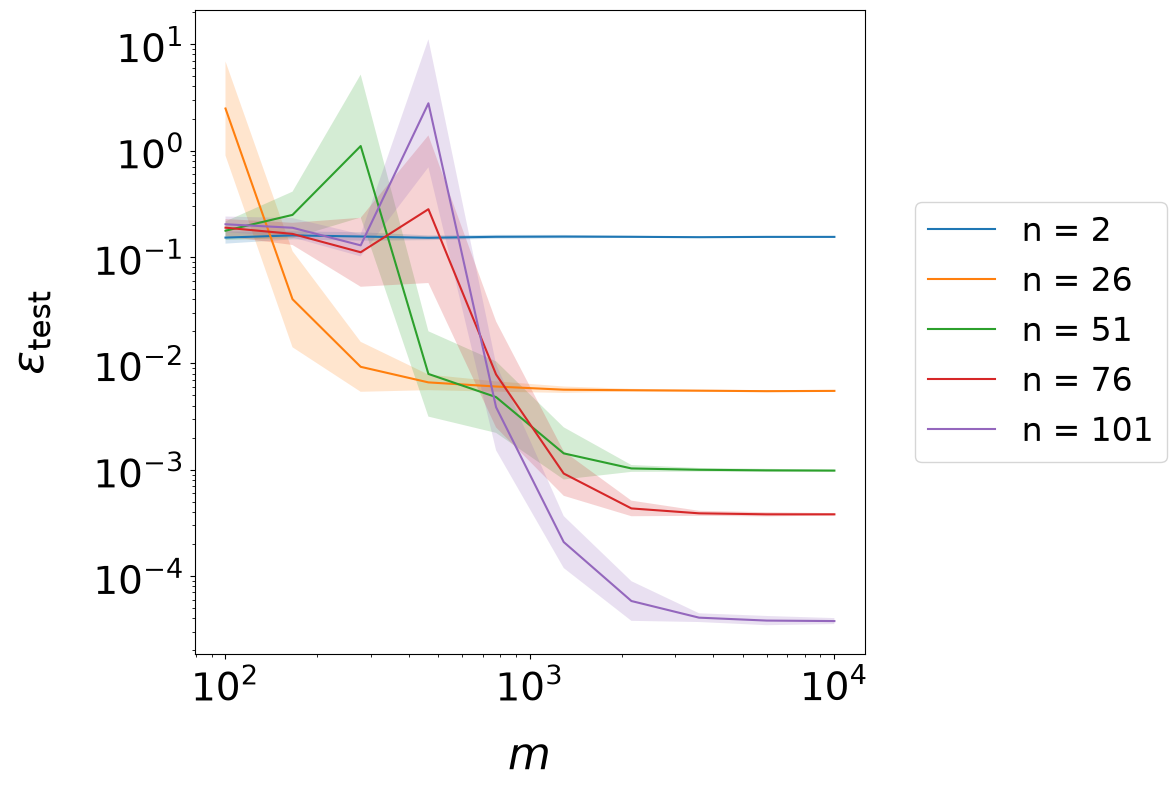

In [66]:

# Plot test RMSE over training set sizes

results_mean = np.mean(MSE, axis=2)
results_std = np.std(MSE, axis=2)
results_relative_std = results_std / results_mean

plt.figure(figsize=(12, 8))

for i, t in enumerate(Para_slep):
    plt.loglog(
        Nsamples,
        results_mean[i, :],
        label=f'n = {t + 1}'
    )

    plt.fill_between(
        Nsamples,
        results_mean[i, :] / (1 + results_relative_std[i, :]),
        results_mean[i, :] * (1 + results_relative_std[i, :]),
        alpha=0.2
    )

plt.xlabel(r'$m$', fontsize=32, labelpad=18)
plt.ylabel(r'$\epsilon_{\mathrm{test}}$', fontsize=32, labelpad=28)

plt.tick_params(axis='both', which='major', labelsize=28)
plt.tick_params(axis='both', which='minor', labelsize=28)

plt.legend(
    fontsize=24,
    loc='center left',
    bbox_to_anchor=(1.05, 0.5),
    ncol=1
)

plt.tight_layout()
plt.savefig("errorvsparams2D.pdf", bbox_inches="tight")
plt.show()
